     Неделя  conv_reg  conv_search  conv_view  conv_book  conv_ride  \
0  Неделя 1  0.653405     0.723127   0.792709   0.785872   0.871173   
1  Неделя 2  0.658673     0.707754   0.788426   0.784390   0.895579   
2  Неделя 3  0.678864     0.741822   0.805241   0.757274   0.861082   
3  Неделя 4  0.679917     0.720823   0.798118   0.755989   0.877715   
4  Неделя 5  0.667020     0.727620   0.798023   0.789719   0.873509   
5  Неделя 6  0.679359     0.709472   0.789774   0.797008   0.907446   
6  Неделя 7  0.669353     0.493459   0.840591   0.793232   0.842622   
7  Неделя 8  0.675320     0.503321   0.812615   0.795555   0.893826   

   conv_total  
0    0.256560  
1    0.258875  
2    0.264176  
3    0.259325  
4    0.267299  
5    0.274835  
6    0.185446  
7    0.196772  


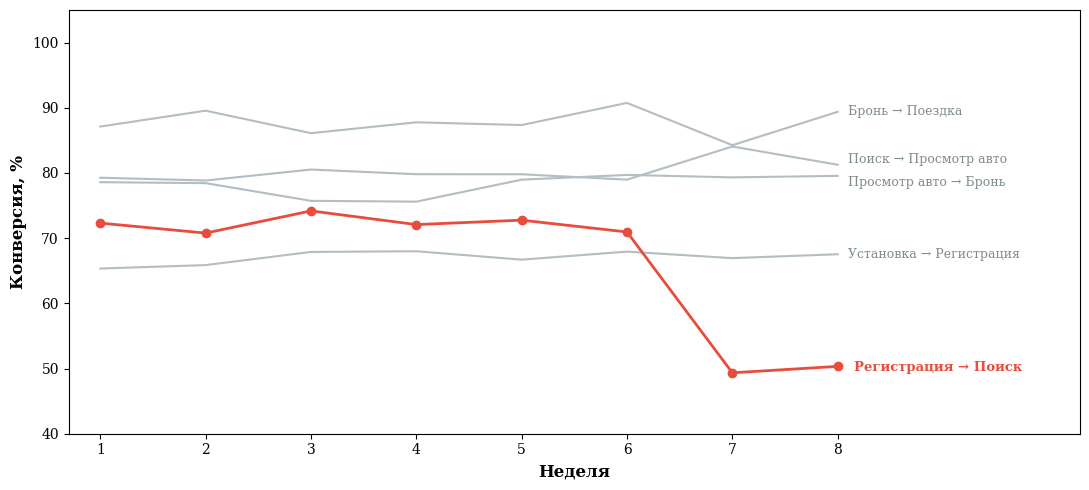

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rc('font', family='serif')
plt.rc('axes', titlesize=18, titleweight='bold')

df = pd.read_excel('dannye-ce1e2d0f-249c-4782-a612-f0d6eeba56c0.xlsx', nrows=56)

df['conv_reg'] = df['Регистрации'] / df['Установки']
df['conv_search'] = df['Открыли поиск'] / df['Регистрации']
df['conv_view'] = df['Просмотрели авто'] / df['Открыли поиск']
df['conv_book'] = df['Забронировали'] / df['Просмотрели авто']
df['conv_ride'] = df['Первая поездка'] / df['Забронировали']
df['conv_total'] = df['Первая поездка'] / df['Установки']

weekly = df.groupby('Неделя').agg({
    'conv_reg': 'mean',
    'conv_search': 'mean',
    'conv_view': 'mean',
    'conv_book': 'mean',
    'conv_ride': 'mean',
    'conv_total': 'mean'
}).reset_index()

print(weekly)

weeks = list(range(1,9))

search_conv = weekly['conv_search'] * 100
reg_conv = weekly['conv_reg'] * 100
view_conv = weekly['conv_view'] * 100
book_conv = weekly['conv_book'] * 100
ride_conv = weekly['conv_ride'] * 100

plt.figure(figsize=(11, 5))
plt.xticks(weeks)

plt.plot(weeks, reg_conv, marker='', linewidth=1.5, color='#b2bec3')
plt.plot(weeks, view_conv, marker='', linewidth=1.5, color='#b2bec3')
plt.plot(weeks, book_conv, marker='', linewidth=1.5, color='#b2bec3')
plt.plot(weeks, ride_conv, marker='', linewidth=1.5, color='#b2bec3')
plt.plot(weeks, search_conv, marker='o', linewidth=2, color='#e74c3c')

plt.ylabel('Конверсия, %', fontsize=12, fontweight='bold')
plt.xlabel('Неделя', fontsize=12, fontweight='bold')
plt.ylim(40, 105)
plt.xlim(0.7, 10.3)

plt.text(8.1, reg_conv.iloc[-1], 'Установка → Регистрация', fontsize=9, color='#7f8c8d', va='center')
plt.text(8.1, view_conv.iloc[-1]+0.8, 'Поиск → Просмотр авто', fontsize=9, color='#7f8c8d', va='center')
plt.text(8.1, book_conv.iloc[-1]-1, 'Просмотр авто → Бронь', fontsize=9, color='#7f8c8d', va='center')
plt.text(8.1, ride_conv.iloc[-1], 'Бронь → Поездка', fontsize=9, color='#7f8c8d', va='center')
plt.text(8.15, search_conv.iloc[-1]-0.1, 'Регистрация → Поиск', fontsize=9.5, color='#e74c3c', va='center', fontweight='bold')


plt.tight_layout()
plt.show()

